In [ ]:
import numpy as np
import pandas as pd


print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Setup Ready ✅")

Setup Ready ✅


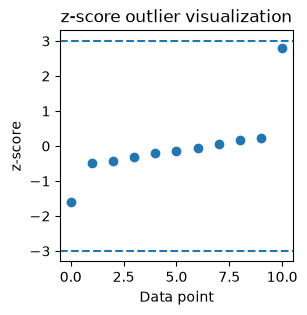

In [ ]:
from matplotlib.lines import lineStyles
from IPython.core.pylabtools import figsize
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([ -20,10,12,15,18,20,22,25,28,30,100])


z_score = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)), z_score)

plt.axhline(3, linestyle = "--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data point")
plt.ylabel("z-score")
plt.title("z-score outlier visualization")

plt.show()

In [ ]:
import seaborn as sns
import pandas as pd

sns.load_dataset('tips')

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [ ]:
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
q1= df['total_bill'].quantile(0.25)
q3= df['total_bill'].quantile(0.75)
iqr= q3-q1

lower= q1-1.5*iqr

upper=q3+1.5*iqr

(df['total_bill']<upper) & (df['total_bill']>lower)

0      True
1      True
2      True
3      True
4      True
       ... 
239    True
240    True
241    True
242    True
243    True
Name: total_bill, Length: 244, dtype: bool

In [ ]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x1ebb6e2d940>,
 'caps': [<matplotlib.lines.Line2D at 0x1ebb6e2dbe0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1ebb6e2d7f0>],
 'medians': [<matplotlib.lines.Line2D at 0x1ebb6e2de80>],
 'fliers': [<matplotlib.lines.Line2D at 0x1ebb6e2dfd0>],
 'means': []}

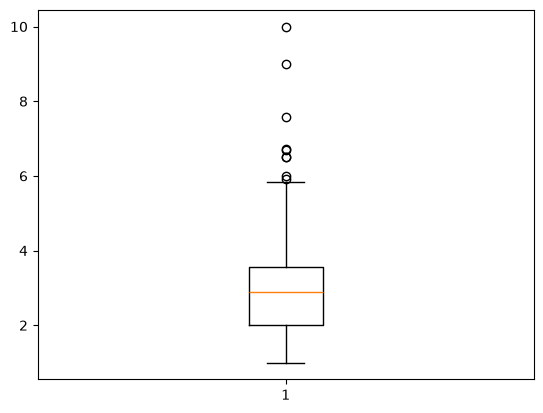

In [ ]:
plt.boxplot(df['tip'])

In [ ]:
q1= df['tip'].quantile(0.25)
q3= df['tip'].quantile(0.75)
iqr= q3-q1
print('iqr-----------',iqr)
lower= q1-1.5*iqr
print('lower-----------',lower)
upper=q3+1.5*iqr
print('upper-----------',upper)

iqr----------- 1.5625
lower----------- -0.34375
upper----------- 5.90625


{'whiskers': [<matplotlib.lines.Line2D at 0x1ebb6ea1010>,
 'caps': [<matplotlib.lines.Line2D at 0x1ebb6ea12b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1ebb6ea0ec0>],
 'medians': [<matplotlib.lines.Line2D at 0x1ebb6ea1550>],
 'fliers': [<matplotlib.lines.Line2D at 0x1ebb6ea16a0>],
 'means': []}

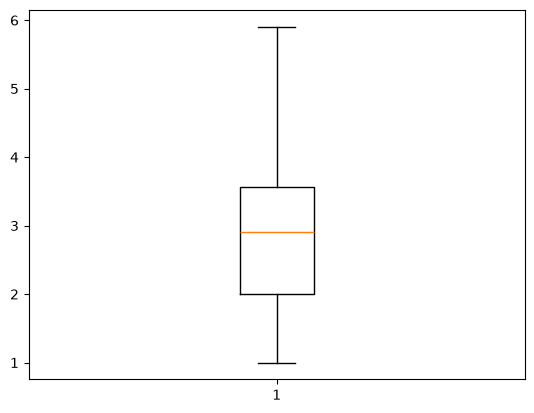

In [ ]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [ ]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [ ]:
num_fea=['total_bill','tip']
ohe_fea=['sex','smoker']
min_max=['tip']

In [ ]:
transformer=ColumnTransformer(
    transformers=[('num',StandardScaler(),num_fea),
    ('cat',OneHotEncoder(),ohe_fea),
    ('min_max',MinMaxScaler(),min_max)],remainder='passthrough'
)

In [ ]:
transformer.fit_transform(df)

array([[-0.3147113050904943, -1.586160695895674, 1.0, ..., 'Sun',
        'Dinner', 2],
       [-1.0632353132988692, -1.0547221187494287, 0.0, ..., 'Sun',
        'Dinner', 3],
       [0.13777989987156145, 0.449657853479943, 0.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.3246295019205694, -0.7767388630113925, 0.0, ..., 'Sat',
        'Dinner', 2],
       [-0.2212865040659901, -0.9811383157599484, 0.0, ..., 'Sat',
        'Dinner', 2],
       [-0.11322890288102155, 0.04085894798283116, 1.0, ..., 'Thur',
        'Dinner', 2]], shape=(244, 10), dtype=object)

In [ ]:
pd.DataFrame(transformer.fit_transform(df),columns=transformer.get_feature_names_out())

,num__total_bill,num__tip,cat__sex_Female,cat__sex_Male,cat__smoker_No,cat__smoker_Yes,min_max__tip,remainder__day,remainder__time,remainder__size
0,-0.314711,-1.586161,1.0,0.0,1.0,0.0,0.002038,Sun,Dinner,2
1,-1.063235,-1.054722,0.0,1.0,1.0,0.0,0.134522,Sun,Dinner,3
2,0.13778,0.449658,0.0,1.0,1.0,0.0,0.509554,Sun,Dinner,3
3,0.438315,0.294314,0.0,1.0,1.0,0.0,0.470828,Sun,Dinner,2
4,0.540745,0.539594,1.0,0.0,1.0,0.0,0.531975,Sun,Dinner,4
...,...,...,...,...,...,...,...,...,...,...
239,1.040511,2.417003,0.0,1.0,1.0,0.0,1.0,Sat,Dinner,3
240,0.832275,-0.776739,1.0,0.0,0.0,1.0,0.203822,Sat,Dinner,2
241,0.32463,-0.776739,0.0,1.0,0.0,1.0,0.203822,Sat,Dinner,2
242,-0.221287,-0.981138,0.0,1.0,1.0,0.0,0.152866,Sat,Dinner,2
